# L2.1 · Estimate the value of an apartment

**PowerPoint slides** 9–14  
**Course data** property_valuations.csv

### The problem

Can size and bedroom count help us guess the recorded value of a Dubai apartment?

### What this demo shows

Start with one number for every apartment, fit a line, and see how the line changes when we give it another clue.

### Why we’re doing it

A value guess can be useful even when it is imperfect. We want to know how large the misses are and whether some kinds of apartments are harder to predict.

**If this is your first ML activity**, open [00 · Your first ML workflow](00_Start_Here_Your_First_ML_Workflow.ipynb) first. For the simpler examples of model types and repeated checking, see [01 · Regression and classification](01_Regression_and_Classification.ipynb) and [03 · K-fold cross-validation](03_K_Fold_Cross_Validation.ipynb).

Here, read the plain-English explanation before each cell. Run **Setup**, then work down the page with **Shift + Enter**.

## Setup · Load the data

Use the same Dubai apartment sample and the same train, validation and test dates as D2.1. The first few lines locate the course data folder. You can
run the whole cell as written.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

working_folder = Path.cwd()
data_folder = next(
    (folder / 'data' for folder in (working_folder, *working_folder.parents)
     if (folder / 'data' / 'property_valuations.csv').is_file()),
    None,
)
if data_folder is None:
    raise FileNotFoundError('Open the extracted course folder in Jupyter or VS Code.')

columns = ["valuation_date", "emirate", "property_type", "size_sqft", "bedrooms", "valuation_aed"]
properties = pd.read_csv(data_folder / "property_valuations.csv", usecols=columns, parse_dates=["valuation_date"])
apartments = properties.query("emirate == 'Dubai' and property_type == 'Apartment'")
apartments = apartments.query("size_sqft > 0 and valuation_aed > 0").dropna()
train = apartments[apartments["valuation_date"] < "2024-01-01"].sample(1000, random_state=42)
validation = apartments[apartments["valuation_date"].dt.year == 2024].sample(500, random_state=42)
test = apartments[apartments["valuation_date"].dt.year == 2025].sample(500, random_state=42)
display(train[["size_sqft", "bedrooms", "valuation_aed"]].head(3))

,size_sqft,bedrooms,valuation_aed
17170,2039.0,3,2417000.0
112596,819.0,1,306000.0
126254,1404.0,2,741000.0


## 1 · Inspect values before modelling

**What we’re doing.** Check the apartments with the highest value per square foot.

**Why we’re doing it.** A very high value might be a typing mistake or a genuinely expensive apartment. Reading a few rows gives us a reason to investigate.

**What to look for.** Look at both area and valuation before interpreting an unusually high ratio.

In [2]:
training_preview = train[["valuation_date", "size_sqft", "valuation_aed"]].copy()
training_preview["AED per sq ft"] = training_preview["valuation_aed"] / training_preview["size_sqft"]
display(training_preview.nlargest(4, "AED per sq ft").round(0))

,valuation_date,size_sqft,valuation_aed,AED per sq ft
145467,2023-09-13,1441.0,4821000.0,3346.0
127217,2022-12-27,395.0,1251000.0,3167.0
966,2018-01-14,951.0,2931000.0,3082.0
143767,2023-08-19,1061.0,3076000.0,2899.0


## 2 · Set two baselines

**What we’re doing.** Guess using either the middle value of all training apartments or the middle value for apartments with the same bedroom count.

**Why we’re doing it.** These simple rules give us two starting points. A more complicated model earns its place by making smaller misses.

**What to look for.** Check whether the bedroom rule improves on the overall guess using the same validation apartments.

In [3]:
typical_value = train["valuation_aed"].median()
value_by_bedrooms = train.groupby("bedrooms")["valuation_aed"].median()
bedroom_guess = validation["bedrooms"].map(value_by_bedrooms).fillna(typical_value)
actual = validation["valuation_aed"]
print(f"Overall median MAE: AED {(actual - typical_value).abs().mean():,.0f}")
print(f"Bedroom median MAE: AED {(actual - bedroom_guess).abs().mean():,.0f}")

Overall median MAE: AED 821,792
Bedroom median MAE: AED 702,002


## 3 · Fit a line and read its slope

**What we’re doing.** Give a line the known sizes and values, then guess the value of a 1,000-square-foot apartment.

**Why we’re doing it.** Size is a clue we can know before guessing. The slope tells us how much the guess changes for each extra square foot.

**What to look for.** Connect the slope to the input unit. The intercept is where this fitted line crosses size zero, outside our practical example.

In [4]:
size_feature = ["size_sqft"]
size_model = LinearRegression().fit(train[size_feature], train["valuation_aed"])
example = pd.DataFrame({"size_sqft": [1000]})
print(f"Slope: AED {size_model.coef_[0]:,.0f} per square foot")
print(f"Intercept: AED {size_model.intercept_:,.0f}")
print(f"Predicted valuation: AED {size_model.predict(example)[0]:,.0f}")

Slope: AED 838 per square foot
Intercept: AED 124,482
Predicted valuation: AED 962,502


### See the line the model learned

Each dot shows an apartment and its recorded value. Read a size along the bottom and move up to the orange line to find the guess.

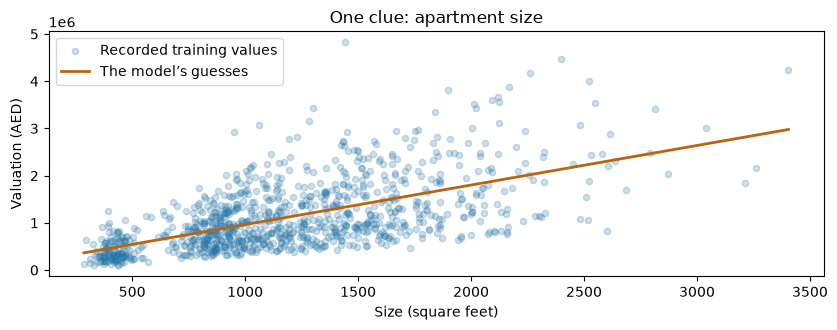

In [5]:
ordered = train.sort_values("size_sqft")
ax = ordered.plot.scatter(x="size_sqft", y="valuation_aed", figsize=(8.5, 3.4),
                          alpha=.23, color="#2676a8", label="Recorded training values")
ax.plot(ordered["size_sqft"], size_model.predict(ordered[size_feature]),
        color="#b96510", linewidth=2, label="The model’s guesses")
ax.set(title="One clue: apartment size", xlabel="Size (square feet)", ylabel="Valuation (AED)")
ax.legend()
plt.tight_layout()
plt.show()

## 4 · Add a feature and read several scores

**What we’re doing.** Add bedroom count as a second clue and compare the new guesses with known values.

**Why we’re doing it.** A single score cannot tell us every kind of mistake. We can look at the typical AED miss, how much big misses matter, and the share of values within 10%.

**What to look for.** MAE is the average absolute miss. RMSE gives extra weight to big misses. R² compares squared errors with predicting a constant. MAPE averages each apartment’s percentage miss.

In [6]:
features = ["size_sqft", "bedrooms"]
two_feature_model = LinearRegression().fit(train[features], train["valuation_aed"])
predictions = pd.Series(two_feature_model.predict(validation[features]), index=validation.index)
residual = actual - predictions
squared_error = (residual ** 2).mean()
relative_error = residual.abs() / actual
print(f"MAE: AED {residual.abs().mean():,.0f}")
print(f"MSE: {squared_error:,.0f} AED²")
print(f"RMSE: AED {squared_error ** 0.5:,.0f}")
print(f"R²: {r2_score(actual, predictions):.2f}")
print(f"MAPE: {relative_error.mean():.1%}")
print(f"Within 10%: {relative_error.le(0.10).mean():.1%}")

MAE: AED 638,231
MSE: 914,039,621,757 AED²
RMSE: AED 956,054
R²: 0.22
MAPE: 39.6%
Within 10%: 14.4%


## 5 · Check residuals

**What we’re doing.** Plot each guess against the recorded value minus that guess.

**Why we’re doing it.** We can see where guesses tend to be too low or where their misses spread out. This difference is called a residual.

**What to look for.** Points above zero were underpredicted. Check whether the spread appears to change across price ranges.

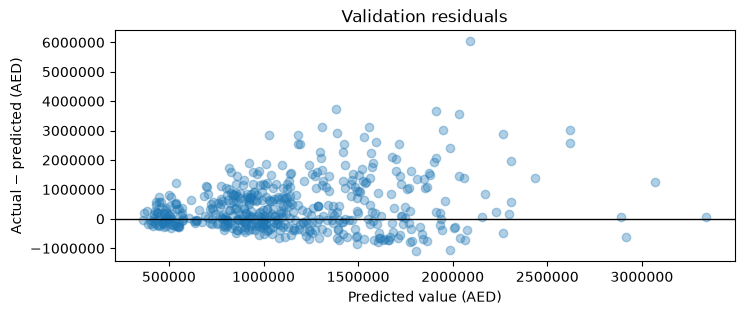

In [7]:
plt.figure(figsize=(8, 3))
plt.scatter(predictions, residual, alpha=0.35)
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Predicted value (AED)")
plt.ylabel("Actual − predicted (AED)")
plt.title("Validation residuals")
plt.ticklabel_format(style="plain", axis="both")
plt.show()

## 6 · Try a log target

**What we’re doing.** Fit a second model after using a log to bring large values closer together. Turn the guesses back into AED.

**Why we’re doing it.** Very expensive properties can dominate the way a line learns. Giving them less weight on the training scale can change the guesses. We check both using the same AED measure.

**What to look for.** The two errors are measured on the same rows. The better approach depends on the data and the chosen metric.

In [8]:
log_model = LinearRegression().fit(train[features], np.log(train["valuation_aed"]))
log_predictions = np.exp(log_model.predict(validation[features]))
print(f"Original target MAE: AED {residual.abs().mean():,.0f}")
print(f"Log target MAE: AED {(actual - log_predictions).abs().mean():,.0f}")

Original target MAE: AED 638,231
Log target MAE: AED 687,851


## 7 · Compare Ridge, Lasso and Elastic Net

**What we’re doing.** Try three ways to keep the model’s weights smaller and compare their validation misses.

**Why we’re doing it.** Large weights can make a guess jump when the input changes a little. Ridge shrinks weights. Lasso can set some to zero. Elastic Net combines the two approaches.

**What to look for.** Each coefficient describes one input on the scaled units. These settings illustrate the penalties. A tuned model would test candidate strengths before opening the final set.

In [9]:
for model in [LinearRegression(), Ridge(alpha=1), Lasso(alpha=50_000), ElasticNet(alpha=10_000)]:
    pipeline = make_pipeline(StandardScaler(), model)
    pipeline.fit(train[features], train["valuation_aed"])
    error = (actual - pipeline.predict(validation[features])).abs().mean()
    print(type(model).__name__, "coefficients", model.coef_.round(0), f"· validation MAE AED {error:,.0f}")

LinearRegression coefficients [504508. -67756.] · validation MAE AED 638,231
Ridge coefficients [500855. -64330.] · validation MAE AED 638,237
Lasso coefficients [392162.      0.] · validation MAE AED 642,922
ElasticNet coefficients [87. 78.] · validation MAE AED 783,941


## 8 · Check by group on validation data

**What we’re doing.** Group apartments by bedroom count and read the size of each group’s misses.

**Why we’re doing it.** One overall number can hide a group that gets worse predictions. A group with very few rows also gives us less evidence.

**What to look for.** Compare mean errors and counts together. A group with very few rows provides limited evidence.

In [10]:
errors_by_group = validation[["bedrooms"]].copy()
errors_by_group["absolute_error"] = residual.abs()
display(errors_by_group.groupby("bedrooms")["absolute_error"].agg(["count", "mean"]).round(0))

,count,mean
bedrooms,,
0,80,245726.0
1,200,501674.0
2,145,755836.0
3,61,1176200.0
4,14,1269863.0


## 9 · Check one chosen model on 2025 data

**What we’re doing.** Choose the better target approach on 2024 and check it on 2025.

**Why we’re doing it.** We record what inputs the model uses and how it handled later apartments, so another person knows what the reported score means.

**What to look for.** The output records the fixed inputs and the method chosen using the validation period.

In [11]:
if (actual - log_predictions).abs().mean() < residual.abs().mean():
    final_predictions = np.exp(log_model.predict(test[features]))
    chosen_target = "log of valuation"
else:
    final_predictions = two_feature_model.predict(test[features])
    chosen_target = "valuation in AED"
print("Inputs:", features, "· learned target:", chosen_target)
print(f"2025 test MAE: AED {(test['valuation_aed'] - final_predictions).abs().mean():,.0f}")

Inputs: ['size_sqft', 'bedrooms'] · learned target: valuation in AED
2025 test MAE: AED 705,063


**Discuss.** A line is easiest to interpret when the relationship is
reasonably linear, errors are fairly independent, their spread is similar
across prices, and the inputs are not strongly redundant. Use the residual
chart and the bedroom table to decide what you would check next.

### Your turn

Change 1,000 to 1,200 in step 3. Use the slope to predict the approximate
change in the estimate before you run the cell.